# Anomaly Detection for Industrial Control Systems using the SWaT Dataset

This notebook implements an anomaly-based intrusion detection system (IDS) for indutrial control systems using the Secure Water Treatment (SWaT) dataset

To preface, before anything, this dataset was obtained from Kaggle(https://www.kaggle.com/datasets/vishala28/swat-dataset-secure-water-treatment-system/data?select=normal.csv). Due to this, there is a chance that the data, whether it be the normal operation data or the attack data, has inconsistencies due to not being from a more official source such as itrust.sutd.edu. The general detection pipeline should still be correct.

The objective of this notebook is to detect abnormal behavior caused by cyber-attacks by learning normal operational patterns from sensor and actuator data and testing the model after learning these patterns against the attack dataset.

The pipeline consists of:

1. Data loading and preprocessing
2. Feature engineering
3. Model training using normal operation data
4. Evaluation on attack scenarios
5. Security-oriented performance metrics

The project focuses on a security-oriented evaluation of anomaly detection, with particular emphasis on attack recall, false positives per hour, and detection latency.

## Detection Pipeline Overview

The intrusion detection pipeline used in this notebook follows these steps:

1. Data loading and inspection  
2. Data preprocessing and cleaning  
3. Feature engineering for sensors and actuators  
4. Feature scaling  
5. Anomaly detection model training on normal data only  
6. Evaluation on attack data using security-focused metrics  
7. Model comparison and analysis

The two anomaly detection models evaluated are Isolation Forest and One-Class SVM. Generally speaking these are technically not the most complex models, however there was moreso an emphasis on the detection pipeline itself

## Data Loading and Inspection

The SWaT dataset containts time-series measurements from sensors and actuators in a water treatment plant. Each record includes process variables and a label indicating whether the system was operating normally or under attack. The following section is responsible for loading the dataset and performing an intial inspection.

For anomaly detection, models are trained on normal system behavior and evaluated on attack data to determine whether deviations in process behavior can be detected.

In [39]:
# load dependencies/libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [40]:
# Load dataset
data = pd.read_csv("dataset/normal.csv")

# Inspect dataset
print(data.head())
print(data.columns)
print(data.shape)

#print any missing elements
print(data.isna().sum())

                 Timestamp    FIT101    LIT101   MV101  P101  P102    AIT201  \
0   28/12/2015 10:00:00 AM  2.427057  522.8467     2.0     2     1  262.0161   
1   28/12/2015 10:00:01 AM  2.446274  522.8860     2.0     2     1  262.0161   
2   28/12/2015 10:00:02 AM  2.489191  522.8467     2.0     2     1  262.0161   
3   28/12/2015 10:00:03 AM  2.534350  522.9645     2.0     2     1  262.0161   
4   28/12/2015 10:00:04 AM  2.569260  523.4748     2.0     2     1  262.0161   

     AIT202    AIT203    FIT201  ...  P501  P502    PIT501    PIT502  \
0  8.396437  328.6337  2.445391  ...     2     1  250.8652  1.649953   
1  8.396437  328.6337  2.445391  ...     2     1  250.8652  1.649953   
2  8.394514  328.6337  2.442316  ...     2     1  250.8812  1.649953   
3  8.394514  328.6337  2.442316  ...     2     1  250.8812  1.649953   
4  8.394514  328.6337  2.443085  ...     2     1  250.8812  1.649953   

     PIT503    FIT601  P601  P602  P603  Normal/Attack  
0  189.5988  0.000128     1  

The dataset contains time-series measurements from both sensors and actuators. Several columns contain missing values due to the way the dataset was either created or exported (possibly due to it being from Kaggle). For the purposes of anomaly detection, rows containing missing values will be removed to ensure consistent feature generation.

In [41]:
# Clean column names
data.columns = data.columns.str.strip()
print(data.columns.tolist())

# Convert timestamp
if "Timestamp" in data.columns:
    data["Timestamp"] = pd.to_datetime(data["Timestamp"], errors="coerce")

print(data["Timestamp"].head())

['Timestamp', 'FIT101', 'LIT101', 'MV101', 'P101', 'P102', 'AIT201', 'AIT202', 'AIT203', 'FIT201', 'MV201', 'P201', 'P202', 'P203', 'P204', 'P205', 'P206', 'DPIT301', 'FIT301', 'LIT301', 'MV301', 'MV302', 'MV303', 'MV304', 'P301', 'P302', 'AIT401', 'AIT402', 'FIT401', 'LIT401', 'P401', 'P402', 'P403', 'P404', 'UV401', 'AIT501', 'AIT502', 'AIT503', 'AIT504', 'FIT501', 'FIT502', 'FIT503', 'FIT504', 'P501', 'P502', 'PIT501', 'PIT502', 'PIT503', 'FIT601', 'P601', 'P602', 'P603', 'Normal/Attack']


C:\Users\Danilo Bodden\AppData\Local\Temp\ipykernel_20088\2805985066.py:7: UserWarning: Parsing dates in  %d/%m/%Y %I:%M:%S %p format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  data["Timestamp"] = pd.to_datetime(data["Timestamp"], errors="coerce")


0   2015-12-28 10:00:00
1   2015-12-28 10:00:01
2   2015-12-28 10:00:02
3   2015-12-28 10:00:03
4   2015-12-28 10:00:04
Name: Timestamp, dtype: datetime64[us]


Although the dataset contains missing values in several columns, removing rows with missing data still leaves a sufficiently large dataset for training the anomaly detection models. Therefore, rows containing missing values are dropped to simplify preprocessing below.

In [42]:
#check for missing values
missing_values = data.isnull().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])

data.columns = data.columns.str.strip()

# find first index where MV101 becomes NaN
first_nan = data["MV101"].isna().idxmax()

print("First missing MV101 row:", first_nan)

#after finding the first index where MV101 is blank/NaN, clean the dataset
data_clean = data.iloc[:first_nan].copy()

print("Clean dataset shape:", data_clean.shape)

# quick check for any other blank entries
print(data_clean.isnull().sum())

Columns with missing values:
Timestamp         5
MV101        991800
AIT201       991800
MV201        991800
P201         991800
P202         991800
P204         991800
MV303        991800
dtype: int64
First missing MV101 row: 395298
Clean dataset shape: (395298, 53)
Timestamp        0
FIT101           0
LIT101           0
MV101            0
P101             0
P102             0
AIT201           0
AIT202           0
AIT203           0
FIT201           0
MV201            0
P201             0
P202             0
P203             0
P204             0
P205             0
P206             0
DPIT301          0
FIT301           0
LIT301           0
MV301            0
MV302            0
MV303            0
MV304            0
P301             0
P302             0
AIT401           0
AIT402           0
FIT401           0
LIT401           0
P401             0
P402             0
P403             0
P404             0
UV401            0
AIT501           0
AIT502           0
AIT503           0
AIT504    

### Sensor and Actuator Identification

Sensors measure physical process variables such as flow, pressure, and chemical properties. Actuators control system behavior through pumps, valves, and other devices.

Columns are classified based on their naming conventions in the SWaT dataset. 

In [43]:
# Lets confirm how many sensors/actuators there are
sensor_cols = [c for c in data_clean.columns if c.startswith(("FIT","LIT","AIT","PIT","DPIT"))]

# If we did not include the "and not c.startwith("PIT")", the actuator columns would include the pressure indicators which are sensors
actuator_cols = [c for c in data_clean.columns if c.startswith(("P","MV","UV")) and not c.startswith("PIT")]

print("Sensors:", len(sensor_cols))
print("Actuators:", len(actuator_cols))

Sensors: 25
Actuators: 26


In [44]:
#quick summary
print("Total rows:", len(data_clean))
print("Total columns:", len(data_clean.columns))
print("Sensors:", len(sensor_cols))
print("Actuators:", len(actuator_cols))

Total rows: 395298
Total columns: 53
Sensors: 25
Actuators: 26


## Exploratory Analysis of Sensor Behavior

Industrial control systems represent physical processes where sensor readings are closely related through system dynamics. Understanding these relationships is important for anomaly detection, since attacks often disrupt expected physical dependencies.

The following visualizations explore sensor behavior and relationships in the SWaT dataset to better understand the structure of the system before constructing anomaly detection features.

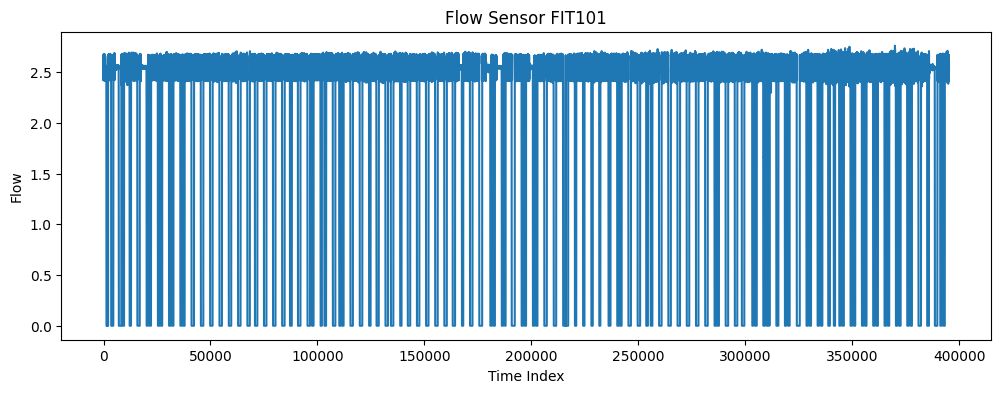

In [45]:
# Visualization for a Flow Sensor
plt.figure(figsize=(12,4))
plt.plot(data_clean["FIT101"])
plt.title("Flow Sensor FIT101")
plt.xlabel("Time Index")
plt.ylabel("Flow")
plt.show()

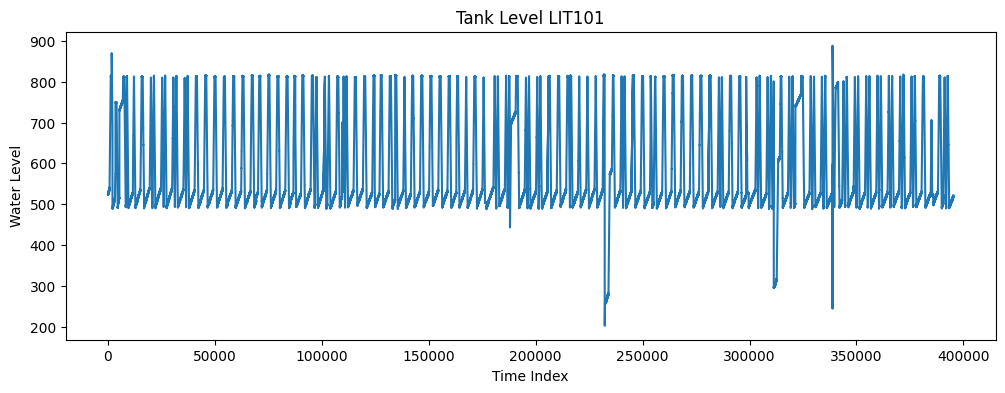

In [46]:
# Visualization for a Tank Level
plt.figure(figsize=(12,4))
plt.plot(data_clean["LIT101"])
plt.title("Tank Level LIT101")
plt.xlabel("Time Index")
plt.ylabel("Water Level")
plt.show()

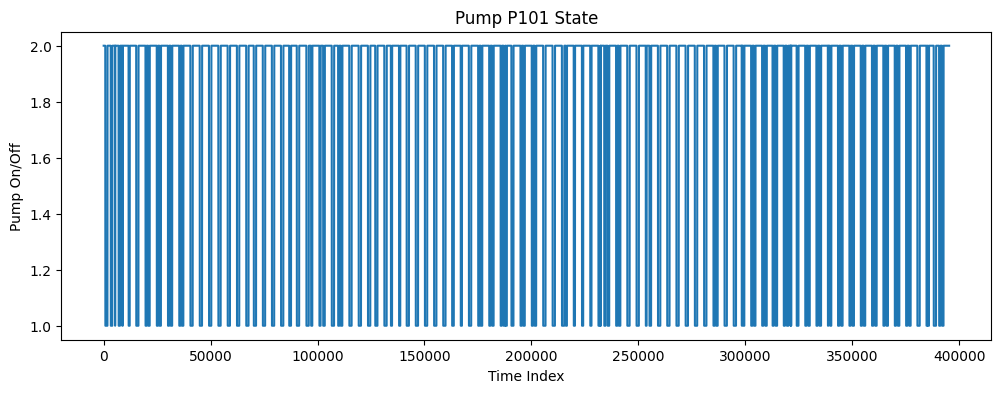

In [47]:
# Visualization for a Pump, which in this case is also an actuator and is either  1 or 2 at all times
plt.figure(figsize=(12,4))
plt.plot(data_clean["P101"])
plt.title("Pump P101 State")
plt.xlabel("Time Index")
plt.ylabel("Pump On/Off")
plt.show()

For now we can assume that 1 is either Low/Off and 2 is either High/On. It is difficult to determine exactly, as I am not personally an expert on the data. Some quick key insights are would be that whenever the Pump is OFF, the flow decreases (or in the dataset is literally 0 for some time), and the Tank level increases to around 800. Otherwise when the Pump is On, the flow increases and the tank level decreases. Shows their relationship/correlation.

So some examples of suspicious states would when the Pump is OFF but the Flow is HIGH or when the Pump is On but the Tank level is rising

### Correlation Analysis

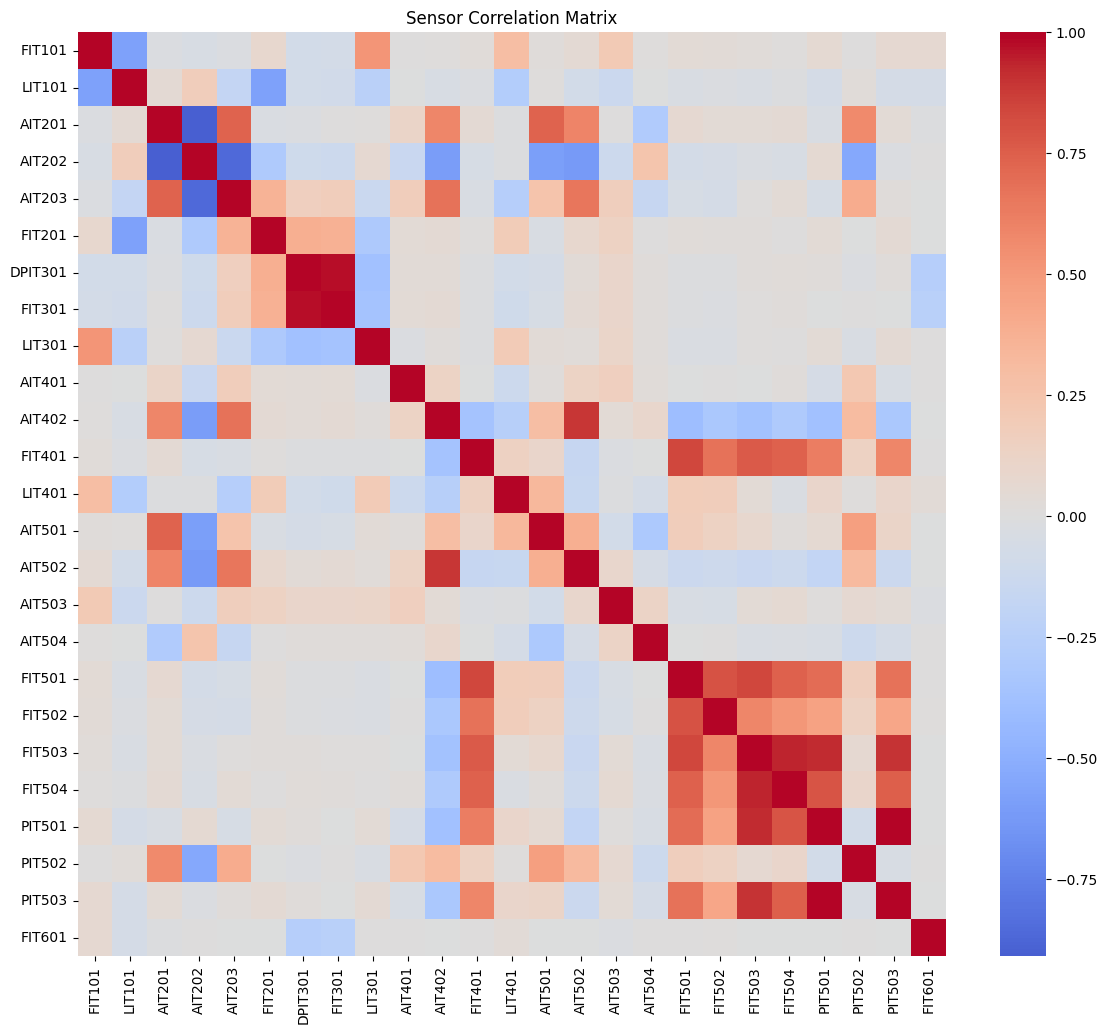

In [48]:
# We will atempt to find relationships between sensors
corr = data_clean[sensor_cols].corr()

plt.figure(figsize=(14,12))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Sensor Correlation Matrix")
plt.show()

The following plot shows the behavior of selected flow sensors across the system. Flow measurements between stages are expected to exhibit correlated behavior due to the sequential nature of the water treatment process.

Through the correlation analysis we can detect each sensor's correlation with each other. For example, what was stated earlier, with the flow rate of stage 1 being inversely correlated with the the tank level indicator of stage 1, which is shown by the blue square and much more obviously. Theres also stuff like the differential pressure in stage 3 being highly correlated with the flow indicator at stage 3 as well. There is also the great example of most of the Sensor and Pressure measurements in stage 5 being highly correlated with each other 

## Feature Engineering

Industrial control system data contains both sensor measurements and actuator states. To improve anomaly detection performance, additional features are derived from the raw signals.

Three types of features are created:

1. Sensor dynamics – rate of change of sensor values  
2. Rolling statistics – moving averages and standard deviations  
3. Actuator switching behavior – detection of state transitions in pumps and valves  

These features help capture temporal process behavior that may indicate abnormal system activity.

Due to raw sensor values often looking normal, creating some new features to ensure we also record any dynamic changes is also something of interest. Sudden deviations can be detected much easier if we add things such as a rate of change feature. We can also include some rolling statistics to obtain some sudden jumps as well. For the actuators, there realistically is only one feature to track, which is how many times it may change. If there happends to be a rapid series of changes, it could indicate some instability or an attack on the control logic.

In [49]:
#for sensors, we should consider introducing features that calculate the rate of change to capture sudden changes and rolling statistics to help detect drift or instability
sensor_features = {}

for sensor in sensor_cols:
    sensor_features[f"{sensor}_rate"] = data_clean[sensor].diff()
    sensor_features[f"{sensor}_mean"] = data_clean[sensor].rolling(20).mean()

sensor_df = pd.DataFrame(sensor_features)

data_clean = pd.concat([data_clean, sensor_df], axis=1)

In [50]:
#for the actuators, since they represent control logic, we would instead create a feature that detects when this control logic is activated which should detect any rapid switching or unexpected control behavior
new_features = {}

for act in actuator_cols:
    new_features[f"{act}_switch"] = data_clean[act].diff().abs()

switch_df = pd.DataFrame(new_features)

data_clean = pd.concat([data_clean, switch_df], axis=1)

The reason we first create a dictionary and then concatenate is due to an error stating that the DataFrame is highly fragmented

In [51]:
#Since some of our new features such as rolling and diff create some NaNs at the start
data_clean = data_clean.dropna()

In [52]:
#removing Timestamp and Normal/Attack 
X = data_clean.drop(columns=["Timestamp", "Normal/Attack"])

print("Total features:", len(data_clean.columns))
print(X.shape)

Total features: 129
(395279, 127)


### Feature Scaling

Many anomaly detection models are sensitive to feature scale. To ensure consistent behavior across different sensors and actuators, all features will be standardized using the StandardScaler.

In [53]:
# lets also scale all of our new features as well
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)

#Ensure that there is no more NaN
print(pd.isna(X_scaled).sum())

(395279, 127)
0


## The Anomaly Detection Model

Industrial control systems typically operate under stable conditions. Instead of learning attack patterns directly, anomaly detection models are trained only on normal system behavior. 

The models then identify deviations from this baseline as potential anomalies. This approach is well suited for ICS environments where attacks are rare but potentially disruptive.

### Training on Normal System Behavior

The anomaly detection models are trained using only data collected during normal system operation. This allows the models to learn the expected behavior of sensors and actuators in the SWaT water treatment process.

Isolation Forest detects anomalies by isolating observations in random decision trees. Anomalies tend to require fewer splits to isolate compared to normal observations.

This model is commonly used for anomaly detection due to its scalability and efficiency.

In [54]:
#Isolation Forest
model = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

model.fit(X_scaled)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.01
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary ` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary `... versionadded:: 0.21",False


In [55]:
# Anomaly Scores
scores = model.decision_function(X_scaled)
predictions = model.predict(X_scaled)

data_clean = data_clean.copy()
data_clean["anomaly_score"] = scores
data_clean["anomaly_label"] = predictions

print(data_clean[["anomaly_score", "anomaly_label"]].head())

    anomaly_score  anomaly_label
19       0.142575              1
20       0.135620              1
21       0.137989              1
22       0.135472              1
23       0.134332              1


## Test the Isolation Forest Model

In [56]:
# load the dataset
attack_data = pd.read_csv("dataset/attack.csv")

print(attack_data.shape)
print(attack_data.columns)

(54621, 53)
Index([' Timestamp', 'FIT101', 'LIT101', ' MV101', 'P101', 'P102', ' AIT201',
       'AIT202', 'AIT203', 'FIT201', ' MV201', ' P201', ' P202', 'P203',
       ' P204', 'P205', 'P206', 'DPIT301', 'FIT301', 'LIT301', 'MV301',
       'MV302', ' MV303', 'MV304', 'P301', 'P302', 'AIT401', 'AIT402',
       'FIT401', 'LIT401', 'P401', 'P402', 'P403', 'P404', 'UV401', 'AIT501',
       'AIT502', 'AIT503', 'AIT504', 'FIT501', 'FIT502', 'FIT503', 'FIT504',
       'P501', 'P502', 'PIT501', 'PIT502', 'PIT503', 'FIT601', 'P601', 'P602',
       'P603', 'Normal/Attack'],
      dtype='str')


In [57]:
# clean the data
attack_data.columns = attack_data.columns.str.strip()

attack_data["Timestamp"] = pd.to_datetime(attack_data["Timestamp"])

C:\Users\Danilo Bodden\AppData\Local\Temp\ipykernel_20088\3339463106.py:4: UserWarning: Parsing dates in  %d/%m/%Y %I:%M:%S %p format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  attack_data["Timestamp"] = pd.to_datetime(attack_data["Timestamp"])


In [58]:
#add the sensor/actuator columns

sensor_prefix = ("FIT", "LIT", "AIT", "PIT", "DPIT")
actuator_prefix = ("P", "MV", "UV")

sensor_cols = [c for c in attack_data.columns if c.startswith(sensor_prefix)]

actuator_cols = [
    c for c in attack_data.columns
    if c.startswith(actuator_prefix) and not c.startswith("PIT")
]

In [59]:
#recreate our engineering featurers from earlier

sensor_features = {}

for sensor in sensor_cols:
    sensor_features[f"{sensor}_rate"] = attack_data[sensor].diff()
    sensor_features[f"{sensor}_mean"] = attack_data[sensor].rolling(20).mean()

sensor_df = pd.DataFrame(sensor_features)

actuator_features = {}

for act in actuator_cols:
    actuator_features[f"{act}_switch"] = attack_data[act].diff().abs()

actuator_df = pd.DataFrame(actuator_features)

In [60]:
# combine everything
attack_data = pd.concat([attack_data, sensor_df, actuator_df], axis=1)

attack_data = attack_data.dropna()

# remove non-feature columns
X_attack = attack_data.drop(columns=["Timestamp", "Normal/Attack"])

# force the same features used during training
X_attack = X_attack[X.columns]

# remove duplicate columns
X_attack = X_attack.loc[:, ~X_attack.columns.duplicated()].copy()
X = X.loc[:, ~X.columns.duplicated()].copy()

# align attack features to training features
X_attack = X_attack.reindex(columns=X.columns)

# verify exact match
print("Same columns and order:", list(X_attack.columns) == list(X.columns))

# refit scaler on cleaned training data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# transform attack data
X_attack_scaled = scaler.transform(X_attack)

print("Train shape:", X.shape)
print("Attack shape:", X_attack.shape)

Same columns and order: True
Train shape: (395279, 127)
Attack shape: (54602, 127)


In [61]:
# run Isolation Forest on attack data
attack_scores = model.decision_function(X_attack_scaled)
attack_preds = model.predict(X_attack_scaled)

attack_data = attack_data.copy()
attack_data["anomaly_score"] = attack_scores
attack_data["anomaly_label"] = attack_preds

In [62]:
# combine datasets
eval_data = pd.concat([data_clean, attack_data])

# build feature matrix
X_eval = eval_data.drop(columns=["Timestamp","Normal/Attack","anomaly_score","anomaly_label"], errors="ignore")

# align columns
X_eval = X_eval[X.columns]

# scale
X_eval_scaled = scaler.transform(X_eval)

# predictions
preds = model.predict(X_eval_scaled)

y_pred = (preds == -1).astype(int)

y_true = eval_data["Normal/Attack"].apply(
    lambda x: 1 if x == "Attack" else 0
)

print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.99      0.97    395279
           1       0.90      0.62      0.73     54602

    accuracy                           0.95    449881
   macro avg       0.92      0.80      0.85    449881
weighted avg       0.94      0.95      0.94    449881



In [63]:
cm = confusion_matrix(y_true, y_pred)
print(cm)

attack_detected = ((y_true == 1) & (y_pred == 1)).sum()
attack_total = (y_true == 1).sum()

detection_rate = attack_detected / attack_total

print("Attack detection rate:", detection_rate)

[[391326   3953]
 [ 20753  33849]]
Attack detection rate: 0.6199223471667704


In [64]:
false_positives = ((y_true == 0) & (y_pred == 1)).sum()

hours = len(attack_data) / 3600

fp_per_hour = false_positives / hours

print("False positives per hour:", fp_per_hour)

False positives per hour: 260.627815830922


In [65]:
# compute the latency canculation
attack_results_if = attack_data.copy().reset_index(drop=True)

attack_indices = attack_results_if.index[attack_results_if["Normal/Attack"] == "Attack"]

latencies = []

for idx in attack_indices:
    window = attack_results_if.iloc[idx:idx+51]
    detected = window[window["anomaly_label"] == -1]

    if len(detected) > 0:
        latency = detected.index[0] - idx
        latencies.append(latency)

if latencies:
    print("Average detection latency:", sum(latencies) / len(latencies), "samples")
else:
    print("No detections found for latency calculation.")

Average detection latency: 1.673382107698101 samples


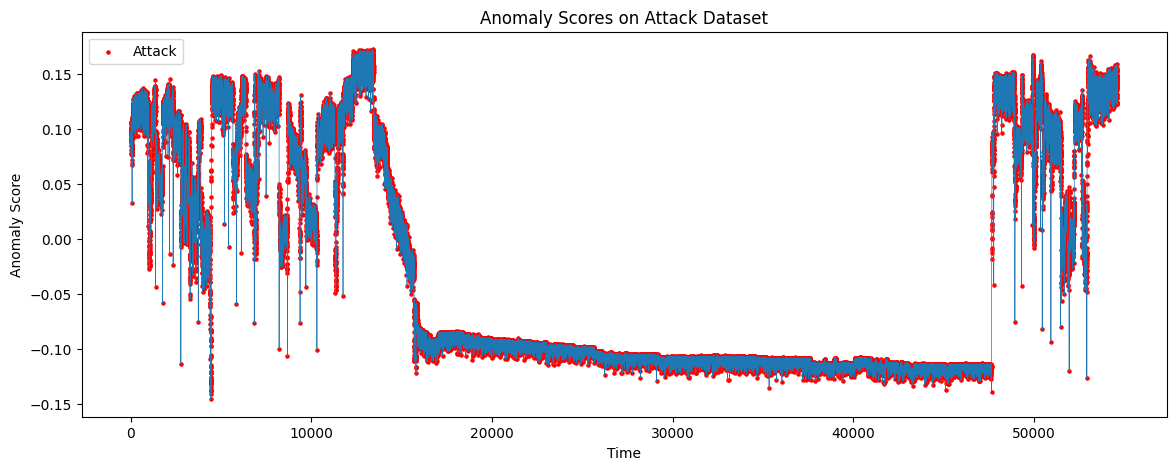

In [66]:
plt.figure(figsize=(14,5))

plt.plot(attack_data["anomaly_score"], linewidth=0.5)

attack_points = attack_data[attack_data["Normal/Attack"] == "Attack"]

plt.scatter(
    attack_points.index,
    attack_points["anomaly_score"],
    color="red",
    s=5,
    label="Attack"
)

plt.title("Anomaly Scores on Attack Dataset")
plt.xlabel("Time")
plt.ylabel("Anomaly Score")
plt.legend()

plt.show()

## One-Class SVM Model

Multiple models should be tested and compared against each other. The One-Class SVM is a standard anomaly detection baseline so it is suited for comparison against the Isolation Forest

In [67]:
ocsvm_model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.01
)

ocsvm_model.fit(X_scaled)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.01
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [68]:
#Predictions on the combined evaluation data
ocsvm_preds = ocsvm_model.predict(X_eval_scaled)

y_pred_ocsvm = (ocsvm_preds == -1).astype(int)

In [69]:
#Compute the same metrics that were done before
print(classification_report(y_true, y_pred_ocsvm, zero_division=0))

cm_ocsvm = confusion_matrix(y_true, y_pred_ocsvm)
print(cm_ocsvm)

              precision    recall  f1-score   support

           0       0.96      0.99      0.98    395279
           1       0.91      0.71      0.80     54602

    accuracy                           0.96    449881
   macro avg       0.93      0.85      0.89    449881
weighted avg       0.95      0.96      0.95    449881

[[391328   3951]
 [ 15914  38688]]


In [70]:
#Compute the security metrics again
attack_detected_ocsvm = ((y_true == 1) & (y_pred_ocsvm == 1)).sum()
attack_total = (y_true == 1).sum()

detection_rate_ocsvm = attack_detected_ocsvm / attack_total

false_positives_ocsvm = ((y_true == 0) & (y_pred_ocsvm == 1)).sum()
hours = len(y_true) / 3600
fp_per_hour_ocsvm = false_positives_ocsvm / hours

print("One-Class SVM detection rate:", detection_rate_ocsvm)
print("One-Class SVM false positives per hour:", fp_per_hour_ocsvm)

One-Class SVM detection rate: 0.7085454745247427
One-Class SVM false positives per hour: 31.61636077095943


In [71]:
#compute the latency calculation as well
eval_results_ocsvm = eval_data.copy().reset_index(drop=True)
eval_results_ocsvm["anomaly_label"] = ocsvm_preds

attack_indices = eval_results_ocsvm.index[eval_results_ocsvm["Normal/Attack"] == "Attack"]

latencies_ocsvm = []

for idx in attack_indices:
    window = eval_results_ocsvm.iloc[idx:idx+51]
    detected = window[window["anomaly_label"] == -1]
    if len(detected) > 0:
        latencies_ocsvm.append(detected.index[0] - idx)

if latencies_ocsvm:
    print("One-Class SVM average detection latency:", sum(latencies_ocsvm) / len(latencies_ocsvm), "samples")
else:
    print("No attack detections found for latency calculation.")

One-Class SVM average detection latency: 1.710345624783262 samples


### Model Comparison

In [72]:
#comparison table
results_table = pd.DataFrame([
    {
        "Model": "Isolation Forest",
        "Attack Recall": detection_rate,
        "FP/hour": fp_per_hour,
    },
    {
        "Model": "One-Class SVM",
        "Attack Recall": detection_rate_ocsvm,
        "FP/hour": fp_per_hour_ocsvm,
    }
])

display(results_table)

,Model,Attack Recall,FP/hour
0,Isolation Forest,0.619922,260.627816
1,One-Class SVM,0.708545,31.616361


The One-Class SVM model achieved higher attack recall while generating significantly fewer false positives per hour compared to Isolation Forest.

This suggests that the One-Class SVM model was better able to capture the boundary of normal system behavior in the SWaT dataset. Lower false positive rates are particularly important in industrial control systems, where excessive alerts can overwhelm operators and reduce trust in the detection system.

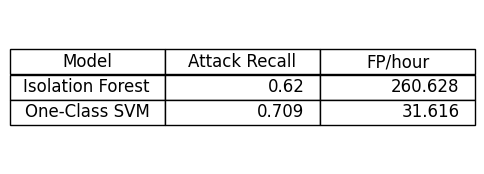

In [87]:
results_table = pd.DataFrame([
    {
        "Model": "Isolation Forest",
        "Attack Recall": detection_rate,
        "FP/hour": fp_per_hour,
    },
    {
        "Model": "One-Class SVM",
        "Attack Recall": detection_rate_ocsvm,
        "FP/hour": fp_per_hour_ocsvm,
    }
])

fig, ax = plt.subplots(figsize=(6,2))
ax.axis('tight')
ax.axis('off')

table = ax.table(
    cellText=results_table.round(3).values,
    colLabels=results_table.columns,
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1,1.5)

plt.savefig("results_comparison.png", bbox_inches='tight', dpi=300)
plt.show()

## Anomaly Inspection

This anomaly inspection is mostly based on the training data of the Isolation Forest, however it still gives a good overview on what sorts of anomalies the Isolation Forest detected in its training set

In [73]:
# create Isolation Forest results dataframe
if_results = data_clean.copy()

if_results["anomaly_score"] = scores
if_results["anomaly_label"] = predictions

print(if_results[["anomaly_score", "anomaly_label"]].head())

    anomaly_score  anomaly_label
19       0.142575              1
20       0.135620              1
21       0.137989              1
22       0.135472              1
23       0.134332              1


In [74]:
#there are still a number of anomalies in the data, however that is also becasue contamination = 0.01 is used, meaning there are around 1% of anomalies chosen based on the training data
print("Anomalies detected:", (data_clean["anomaly_label"] == -1).sum())
print("Total samples:", len(data_clean))

Anomalies detected: 3953
Total samples: 395279


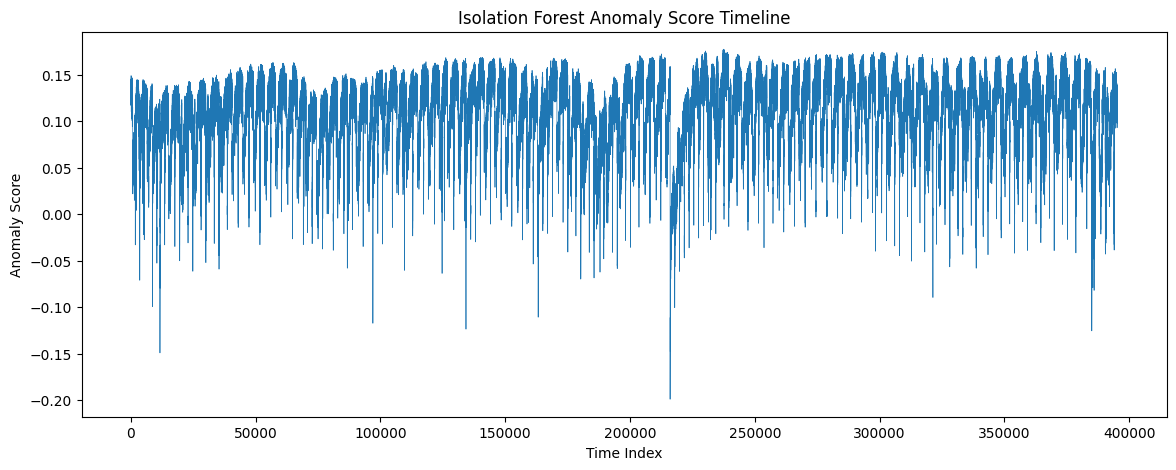

In [75]:
# Visualization
plt.figure(figsize=(14,5))

plt.plot(data_clean["anomaly_score"], linewidth=0.5)

plt.title("Isolation Forest Anomaly Score Timeline")
plt.xlabel("Time Index")
plt.ylabel("Anomaly Score")

plt.show()

Lets find our most anomalous points and inspect the sensor and actuator values for those rows

In [76]:
# 10 most unsual values
lowest = data_clean.sort_values("anomaly_score").head(10)

print(lowest[["anomaly_score"]])

        anomaly_score
216071      -0.199067
11635       -0.149236
216145      -0.147929
216142      -0.139978
216146      -0.139612
216147      -0.137804
216149      -0.135210
216148      -0.134348
216143      -0.133891
216151      -0.129883


In [77]:
# our engineering sensor values
sensor_engineered = [
    c for c in data_clean.columns
    if "_rate" in c or "_mean" in c or "_std" in c
]

# combine raw sensors and engineered sensor features
sensor_all = sensor_cols + sensor_engineered

# inspect the sensor values for those 10 anomaly rows
lowest_sensors = lowest[["anomaly_score"] + sensor_all]

display(lowest_sensors)

,anomaly_score,FIT101,LIT101,AIT201,AIT202,AIT203,FIT201,DPIT301,FIT301,LIT301,...,FIT504_rate,FIT504_mean,PIT501_rate,PIT501_mean,PIT502_rate,PIT502_mean,PIT503_rate,PIT503_mean,FIT601_rate,FIT601_mean
216071,-0.199067,0.000000,813.5919,198.3786,8.525249,370.4948,0.0,2.378513,0.000000,1015.9650,...,-0.306569,0.291240,-238.881066,236.194242,-0.849005,0.790536,-183.670821,177.535409,0.0,0.000000
11635,-0.149236,2.427377,551.8152,263.1377,8.421751,319.0720,0.0,2.785069,0.414694,1010.4380,...,-0.004804,0.307715,-2.371200,245.982605,-0.144170,1.738858,-2.819800,185.438815,0.0,0.000128
216145,-0.147929,0.000000,814.1807,198.5068,8.523327,370.3922,0.0,20.311800,2.210550,988.3684,...,0.050283,0.009733,22.574300,43.302194,0.016019,0.309166,17.671700,28.502308,0.0,0.000000
216142,-0.139978,0.000000,814.2985,198.3786,8.523327,370.3922,0.0,20.311800,2.210550,989.8904,...,0.000064,0.000003,28.277960,21.279798,0.128152,0.152180,21.324660,11.861542,0.0,0.000000
216146,-0.139612,0.000000,813.9844,198.5068,8.521405,370.3922,0.0,20.311800,2.212343,988.0480,...,0.053358,0.018115,17.639700,52.710036,0.112132,0.367635,14.563600,35.706392,0.0,0.000000
216147,-0.137804,0.000000,813.9844,198.5068,8.519803,370.3922,0.0,20.311800,2.212343,987.2068,...,0.049899,0.028991,14.884100,62.862082,0.000000,0.426104,10.734400,43.447195,0.0,0.000000
216149,-0.135210,0.000000,814.1415,198.5068,8.519803,370.3922,0.0,20.276590,2.212343,986.7662,...,0.018384,0.055802,7.161600,84.852436,0.000000,0.543043,5.783700,60.315466,0.0,0.000000
216148,-0.134348,0.000000,814.2200,198.5068,8.519803,370.3922,0.0,20.292590,2.212343,987.0466,...,0.041380,0.041937,13.281800,73.678219,0.000000,0.484574,10.974800,51.736738,0.0,0.000000
216143,-0.133891,0.000000,814.6125,198.3786,8.523327,370.3922,0.0,20.343810,2.210550,989.1695,...,0.016270,0.000820,28.774700,27.379195,0.016019,0.204242,21.773260,16.434087,0.0,0.000000
216151,-0.129883,0.000000,813.7097,198.5068,8.519803,370.5460,0.0,20.263780,2.212343,985.3644,...,0.010505,0.085408,5.191000,108.101280,-0.144170,0.652773,3.572800,78.132213,0.0,0.000000


In [78]:
# inspect the actuator values for those 10 points
actuator_features = actuator_cols + [f"{a}_switch" for a in actuator_cols]

lowest_actuators = lowest[["anomaly_score"] + actuator_features]

display(lowest_actuators)

,anomaly_score,MV101,P101,P102,MV201,P201,P202,P203,P204,P205,...,P401_switch,P402_switch,P403_switch,P404_switch,UV401_switch,P501_switch,P502_switch,P601_switch,P602_switch,P603_switch
216071,-0.199067,1.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
11635,-0.149236,2.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
216145,-0.147929,1.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
216142,-0.139978,1.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
216146,-0.139612,1.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
216147,-0.137804,1.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
216149,-0.135210,1.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
216148,-0.134348,1.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
216143,-0.133891,1.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
216151,-0.129883,1.0,1,1,1.0,1.0,1.0,1,1.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [79]:
# create some csv files for anomaly inspection
lowest_sensors.to_csv("anomaly_sensors.csv")
lowest_actuators.to_csv("anomaly_actuators.csv")

Some interesting points to consider regarding these anomalies. There are many anomalies that occur around the same points from 216071 to 216151 other than the one outlier in entry 11635.

In [80]:
feature_cols = X.columns.tolist()

top_n = 100

most_anomalous = data_clean.nsmallest(top_n, "anomaly_score")

print(most_anomalous[["anomaly_score"]].head())
print("Number of anomaly rows used:", len(most_anomalous))

baseline_mean = data_clean[feature_cols].mean()
baseline_std = data_clean[feature_cols].std()

epsilon = 1e-8

z_deviation = ((most_anomalous[feature_cols] - baseline_mean) / (baseline_std + epsilon)).abs()

feature_importance = z_deviation.mean().sort_values(ascending=False)

print(feature_importance.head(20))

        anomaly_score
216071      -0.199067
11635       -0.149236
216145      -0.147929
216142      -0.139978
216146      -0.139612
Number of anomaly rows used: 100
FIT501_mean    43.976403
P402           42.112711
FIT503_mean    41.142999
FIT501         40.612841
PIT501_mean    39.688100
PIT503_mean    39.347552
FIT502_mean    38.473842
FIT503         38.226498
PIT501         37.234165
PIT503         37.029267
FIT401_mean    35.330250
FIT504_mean    32.396233
FIT401         31.706000
P501           30.808642
UV401          30.567051
FIT502         30.209245
FIT504         30.079093
AIT402         24.336547
AIT402_mean    22.922676
P403           16.241870
dtype: float64


The higher value of the feature, means taht this feature tends to be more unusual during anomalies than during normal operation

In [81]:
sensor_raw = [c for c in feature_cols if c in sensor_cols]
sensor_eng = [c for c in feature_cols if any(x in c for x in ["_rate", "_mean", "_std"])]
actuator_raw = [c for c in feature_cols if c in actuator_cols]
actuator_switch = [c for c in feature_cols if c.endswith("_switch")]

print("Top raw sensor features:")
print(feature_importance.loc[sensor_raw].sort_values(ascending=False).head(10))

print("\nTop engineered sensor features:")
print(feature_importance.loc[sensor_eng].sort_values(ascending=False).head(10))

print("\nTop raw actuator features:")
print(feature_importance.loc[actuator_raw].sort_values(ascending=False).head(10))

print("\nTop actuator switch features:")
print(feature_importance.loc[actuator_switch].sort_values(ascending=False).head(10))

Top raw sensor features:
FIT501    40.612841
FIT503    38.226498
PIT501    37.234165
PIT503    37.029267
FIT401    31.706000
FIT502    30.209245
FIT504    30.079093
AIT402    24.336547
AIT502     8.698608
AIT504     8.371293
dtype: float64

Top engineered sensor features:
FIT501_mean    43.976403
FIT503_mean    41.142999
PIT501_mean    39.688100
PIT503_mean    39.347552
FIT502_mean    38.473842
FIT401_mean    35.330250
FIT504_mean    32.396233
AIT402_mean    22.922676
PIT503_rate    12.494007
LIT401_rate    12.416717
dtype: float64

Top raw actuator features:
P402     42.112711
P501     30.808642
UV401    30.567051
P403     16.241870
MV304     2.185309
P101      1.599515
P205      1.590593
P203      1.590388
MV201     1.550882
MV302     1.422208
dtype: float64

Top actuator switch features:
P501_switch     5.137173
UV401_switch    5.137173
P402_switch     4.447857
P403_switch     4.447857
P205_switch     2.390006
P101_switch     2.380833
P203_switch     2.380833
P302_switch     1.26933

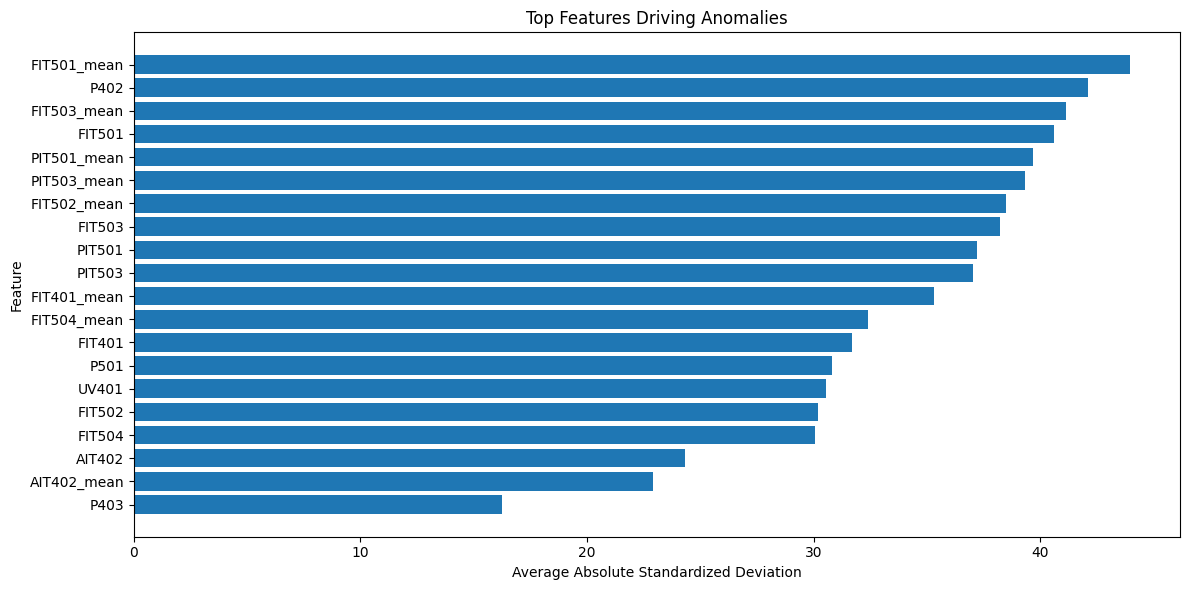

In [82]:
top_features = feature_importance.head(20)

plt.figure(figsize=(12, 6))
plt.barh(top_features.index[::-1], top_features.values[::-1])
plt.title("Top Features Driving Anomalies")
plt.xlabel("Average Absolute Standardized Deviation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [83]:
top_n = 20
most_anomalous = data_clean.nsmallest(top_n, "anomaly_score")
anomaly_features = most_anomalous[feature_cols]

baseline_mean = data_clean[feature_cols].mean()
baseline_std = data_clean[feature_cols].std()

epsilon = 1e-8

z_scores = ((anomaly_features - baseline_mean) / (baseline_std + epsilon)).abs()

top_features = feature_importance.head(20).index.tolist()

z_subset = z_scores[top_features]

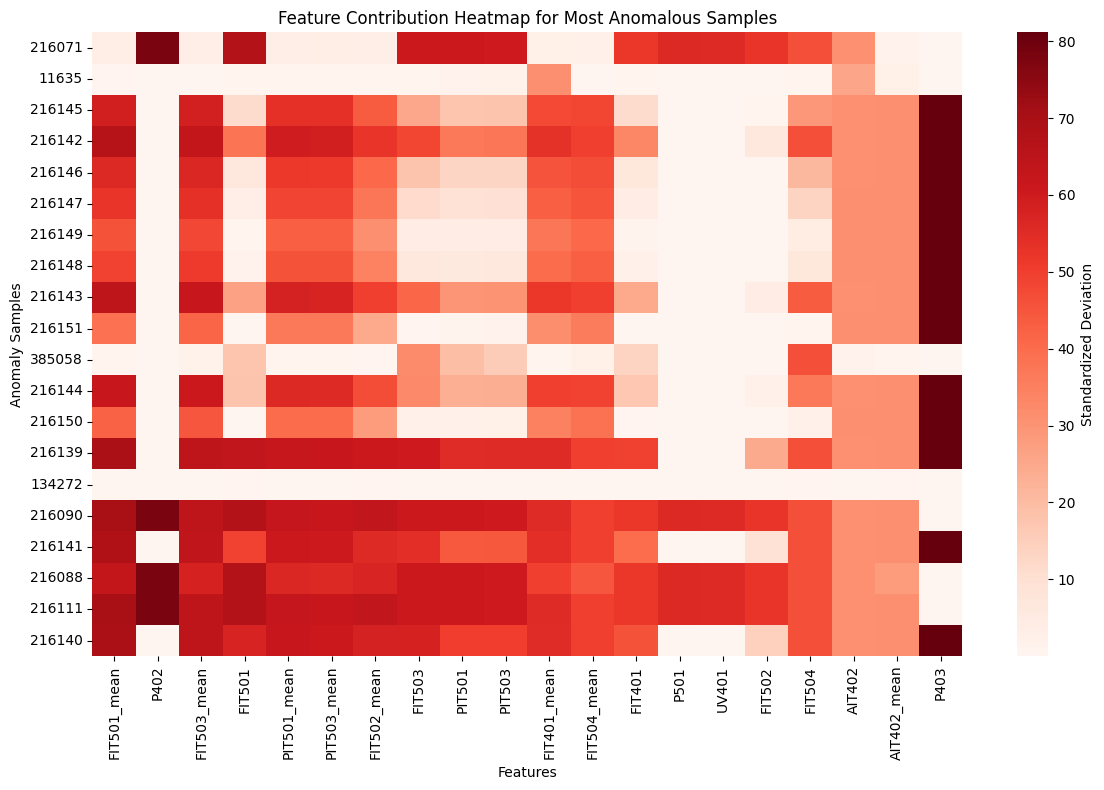

In [84]:
plt.figure(figsize=(12,8))

sns.heatmap(
    z_subset,
    cmap="Reds",
    cbar_kws={"label": "Standardized Deviation"}
)

plt.title("Feature Contribution Heatmap for Most Anomalous Samples")
plt.xlabel("Features")
plt.ylabel("Anomaly Samples")

plt.tight_layout()
plt.show()

The top anomalies mostly include many things at stage 5. Our sensor is mostly flagging those deviation at this moemnt.

## Timeline Anomaly Scores

This a timeline of the Anomaly Scores of the relatively best Model in this Notebook, the One-Class SVM

In [85]:
timeline_df = eval_data.copy().reset_index(drop=True)

timeline_df["anomaly_score"] = ocsvm_model.decision_function(X_eval_scaled)
timeline_df["prediction"] = ocsvm_preds

attack_start = len(data_clean)

attack_section = timeline_df.iloc[attack_start-5000:attack_start+60000]

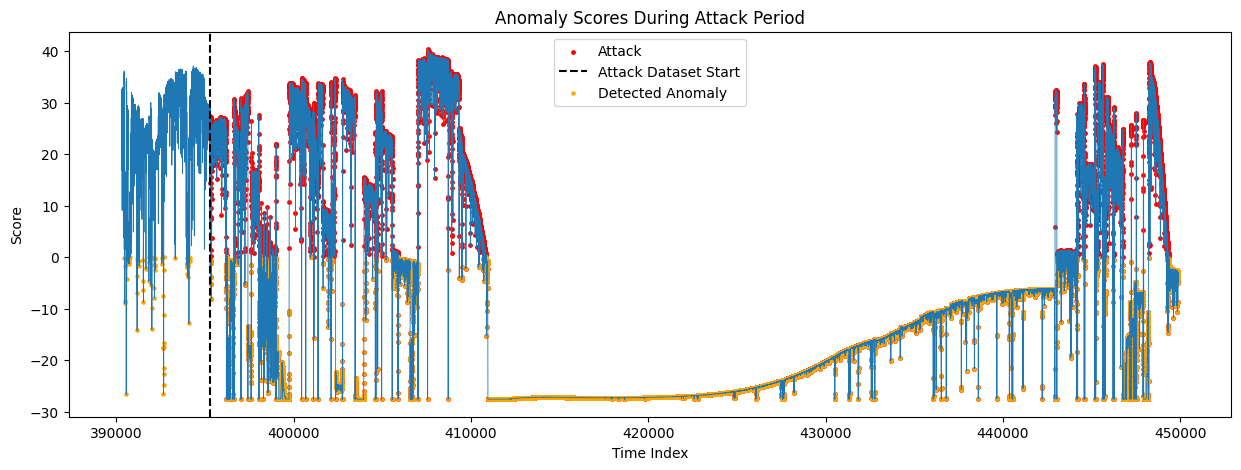

In [86]:
plt.figure(figsize=(15,5))

plt.plot(
    attack_section.index,
    attack_section["anomaly_score"],
    linewidth=0.6
)

attack_points = attack_section[attack_section["Normal/Attack"] == "Attack"]

plt.scatter(
    attack_points.index,
    attack_points["anomaly_score"],
    color="red",
    s=6,
    label="Attack"
)

plt.axvline(x=len(data_clean), color='black', linestyle='--', label='Attack Dataset Start')

detected = attack_section[attack_section["prediction"] == -1]

plt.scatter(
    detected.index,
    detected["anomaly_score"],
    color="orange",
    s=5,
    label="Detected Anomaly"
)

plt.legend()
plt.title("Anomaly Scores During Attack Period")
plt.xlabel("Time Index")
plt.ylabel("Score")

plt.show()

## Limitations

Several limitations should be noted in this analysis.

The attack dataset used in this experiment contains only attack-labeled samples without normal intervals separating individual attack events. Because of this structure, event-level attack detection metrics could not be reliably computed.

Additionally, the anomaly detection models rely on statistical patterns in sensor and actuator behavior. Sophisticated attackers who mimic normal process dynamics may potentially evade detection. It is something very important to consider.

Future work could explore more advanced temporal models or incorporate additional process constraints to improve detection robustness. 